# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name: Habibullah**
- **Student ID: 023-24-0077**
- **Section: D**
- **GitHub:** https://github.com/Habibullah-Gabol/machine-learning-lab
- **Kaggle:**
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.datasets import load_wine

from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    adjusted_rand_score
)

SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [4]:
# YOUR CODE HERE

df = pd.read_csv("Dataset/Mall_Customers.csv")

df = df.rename(columns={
    'Annual Income (k$)': 'Income',
    'Spending Score (1-100)': 'Spending'
})

df.head()

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nGender Distribution:")
print(df['Gender'].value_counts())

print("\nStatistical Summary:")
print(df[['Age', 'Income', 'Spending']].describe())

Dataset Shape: (200, 5)

Missing Values:
CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64

Duplicate Rows:
0

Gender Distribution:
Gender
Female    112
Male       88
Name: count, dtype: int64

Statistical Summary:
              Age      Income    Spending
count  200.000000  200.000000  200.000000
mean    38.850000   60.560000   50.200000
std     13.969007   26.264721   25.823522
min     18.000000   15.000000    1.000000
25%     28.750000   41.500000   34.750000
50%     36.000000   61.500000   50.000000
75%     49.000000   78.000000   73.000000
max     70.000000  137.000000   99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


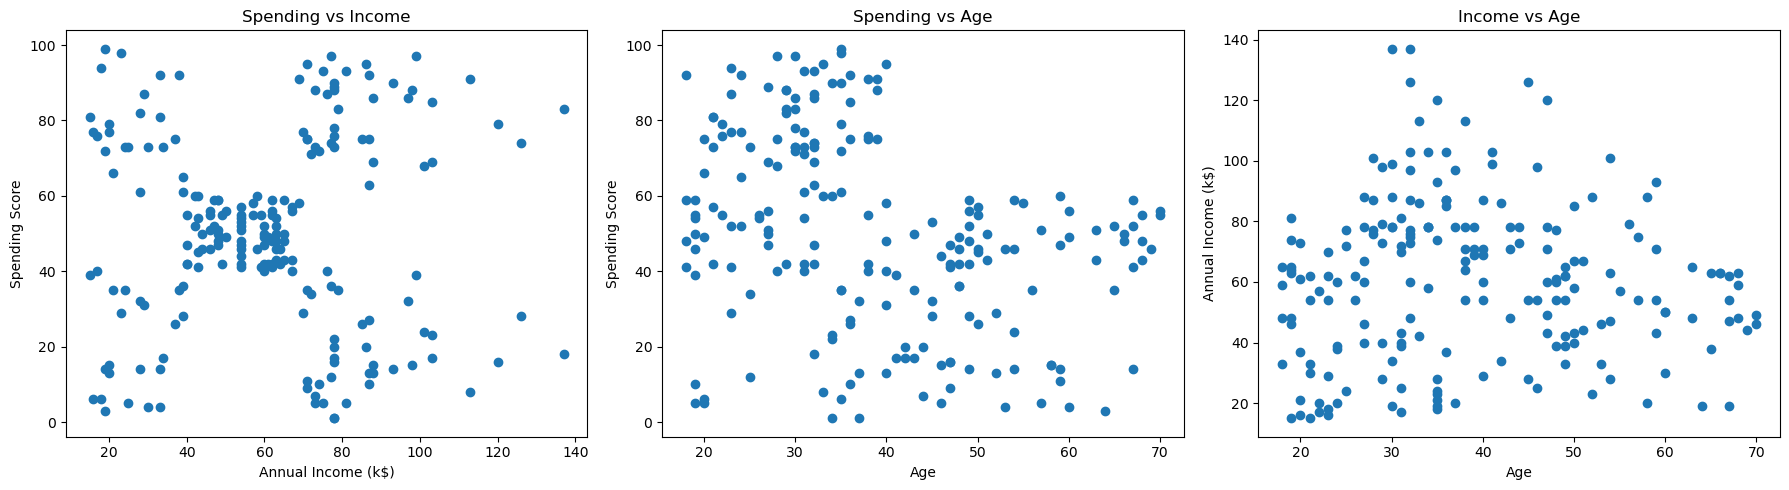

In [5]:
# YOUR CODE HERE

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Spending vs Income
axes[0].scatter(df['Income'], df['Spending'])
axes[0].set_title('Spending vs Income')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score')

# Plot 2: Spending vs Age
axes[1].scatter(df['Age'], df['Spending'])
axes[1].set_title('Spending vs Age')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Spending Score')

# Plot 3: Income vs Age
axes[2].scatter(df['Age'], df['Income'])
axes[2].set_title('Income vs Age')
axes[2].set_xlabel('Age')
axes[2].set_ylabel('Annual Income (k$)')

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a) In the Spending vs Income plot, approximately five groups are visible: low-income/low-spending, low-income/high-spending, medium-income/medium-spending, high-income/low-spending, and high-income/high-spending customers. The Spending vs Age plot shows some patterns but considerable overlap. The Income vs Age plot does not show clearly separated groups. Therefore, Spending vs Income provides the clearest visualization of potential customer segments.

(b) K-Means is an unsupervised learning algorithm, and the dataset does not contain predefined target labels. Therefore, there are no correct cluster labels against which to calculate classification accuracy. A traditional train/test split is also unnecessary because our objective is to discover hidden groups rather than predict a target variable. We evaluate clustering using inertia, silhouette score, visualizations, and domain knowledge.

(c)

(d)


---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [6]:
# YOUR CODE HERE

# Given data points
X = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])

centroids = np.array([4.0, 11.0])

iteration = 0

while True:

    iteration += 1

    distances = np.abs(X[:, None] - centroids[None, :])

    labels = distances.argmin(axis=1)

    new_centroids = np.array([
        X[labels == k].mean()
        for k in range(2)
    ])

    print(f"\nIteration {iteration}")

    for k in range(2):
        print(f"Cluster {k+1}: {X[labels == k]}")

    print("New Centroids:", new_centroids)

    if np.allclose(centroids, new_centroids):
        centroids = new_centroids
        break

    centroids = new_centroids

inertia = np.sum((X - centroids[labels]) ** 2)

print("\nFinal Results")
print("Final Centroids:", centroids)
print("Final Inertia:", inertia)
print("Total Iterations:", iteration)


Iteration 1
Cluster 1: [2 4 3]
Cluster 2: [10 12 20 30 11 25]
New Centroids: [ 3. 18.]

Iteration 2
Cluster 1: [ 2  4 10  3]
Cluster 2: [12 20 30 11 25]
New Centroids: [ 4.75 19.6 ]

Iteration 3
Cluster 1: [ 2  4 10 12  3 11]
Cluster 2: [20 30 25]
New Centroids: [ 7. 25.]

Iteration 4
Cluster 1: [ 2  4 10 12  3 11]
Cluster 2: [20 30 25]
New Centroids: [ 7. 25.]

Final Results
Final Centroids: [ 7. 25.]
Final Inertia: 150.0
Total Iterations: 4


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [7]:
# YOUR CODE HERE

# Given data: Height and Weight
X = np.array([
    [185, 72],  # P1
    [170, 56],  # P2
    [168, 60],  # P3
    [179, 68],  # P4
    [182, 72],  # P5
    [188, 77]   # P6
], dtype=float)

centroids = X[[0, 1]].copy()

iteration = 0

while True:

    iteration += 1

    distances = np.linalg.norm(
        X[:, None, :] - centroids[None, :, :],
        axis=2
    )

    labels = distances.argmin(axis=1)

    new_centroids = np.array([
        X[labels == k].mean(axis=0)
        for k in range(2)
    ])

    print(f"\nIteration {iteration}")

    for k in range(2):
        print(f"Cluster {k+1}:")
        print(X[labels == k])

    print("New Centroids:")
    print(new_centroids)

    if np.allclose(centroids, new_centroids):
        centroids = new_centroids
        break

    centroids = new_centroids

final_distances = np.linalg.norm(
    X[:, None, :] - centroids[None, :, :],
    axis=2
)

print("\nFinal Distance Table:")
print(pd.DataFrame(
    final_distances,
    columns=['Distance to C1', 'Distance to C2'],
    index=['P1', 'P2', 'P3', 'P4', 'P5', 'P6']
).round(2))

print("\nFinal Centroids:")
print(centroids)

print("\nFinal Cluster Assignments:")
for k in range(2):
    print(f"Cluster {k+1}: {['P1','P2','P3','P4','P5','P6'][0:6] if False else np.array(['P1','P2','P3','P4','P5','P6'])[labels == k]}")

print("\nTotal Iterations:", iteration)


Iteration 1
Cluster 1:
[[185.  72.]
 [179.  68.]
 [182.  72.]
 [188.  77.]]
Cluster 2:
[[170.  56.]
 [168.  60.]]
New Centroids:
[[183.5   72.25]
 [169.    58.  ]]

Iteration 2
Cluster 1:
[[185.  72.]
 [179.  68.]
 [182.  72.]
 [188.  77.]]
Cluster 2:
[[170.  56.]
 [168.  60.]]
New Centroids:
[[183.5   72.25]
 [169.    58.  ]]

Final Distance Table:
    Distance to C1  Distance to C2
P1            1.52           21.26
P2           21.13            2.24
P3           19.76            2.24
P4            6.19           14.14
P5            1.52           19.10
P6            6.54           26.87

Final Centroids:
[[183.5   72.25]
 [169.    58.  ]]

Final Cluster Assignments:
Cluster 1: ['P1' 'P4' 'P5' 'P6']
Cluster 2: ['P2' 'P3']

Total Iterations: 2


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [8]:
# YOUR CODE HERE

def my_kmeans(X, init_centroids, max_iter=100):

    # Convert inputs into NumPy arrays
    X = np.asarray(X, dtype=float)
    centroids = np.asarray(init_centroids, dtype=float).copy()

    iterations = 0

    for i in range(max_iter):

        iterations += 1

        distances = np.linalg.norm(
            X[:, None, :] - centroids[None, :, :],
            axis=2
        )

        labels = distances.argmin(axis=1)

        new_centroids = centroids.copy()

        for k in range(len(centroids)):

            cluster_points = X[labels == k]

            if len(cluster_points) > 0:
                new_centroids[k] = cluster_points.mean(axis=0)

        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    distances = np.linalg.norm(
        X[:, None, :] - centroids[None, :, :],
        axis=2
    )

    labels = distances.argmin(axis=1)

    inertia = np.sum(
        (X - centroids[labels]) ** 2
    )

    return labels, centroids, inertia, iterations

In [9]:
# YOUR CODE HERE

X = np.array([
    [2], [4], [10], [12], [3],
    [20], [30], [11], [25]
])

initial_centroids = np.array([
    [4],
    [11]
])

labels, final_centroids, inertia, iterations = my_kmeans(
    X,
    initial_centroids
)

print("Cluster Assignments:", labels)

for k in range(len(final_centroids)):
    print(f"Cluster {k+1}:", X[labels == k].flatten())

print("\nFinal Centroids:")
print(final_centroids.flatten())

print("Final Inertia:", inertia)
print("Total Iterations:", iterations)

Cluster Assignments: [0 0 0 0 0 1 1 0 1]
Cluster 1: [ 2  4 10 12  3 11]
Cluster 2: [20 30 25]

Final Centroids:
[ 7. 25.]
Final Inertia: 150.0
Total Iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [10]:
# YOUR CODE HERE

X2 = df[['Income', 'Spending']].values

initial_centroids = X2[:5].copy()


my_labels, my_centroids, my_inertia, my_iterations = my_kmeans(
    X2,
    initial_centroids
)


sk_model = KMeans(
    n_clusters=5,
    init=initial_centroids,
    n_init=1,
    tol=0,
    algorithm='lloyd'
)

sk_model.fit(X2)


print("=" * 45)
print("CUSTOM K-MEANS")
print("=" * 45)
print("Iterations:", my_iterations)
print("Inertia:", my_inertia)
print("Centroids:\n", my_centroids)


print("\n" + "=" * 45)
print("SCIKIT-LEARN K-MEANS")
print("=" * 45)
print("Iterations:", sk_model.n_iter_)
print("Inertia:", sk_model.inertia_)
print("Centroids:\n", sk_model.cluster_centers_)


print("\n" + "=" * 45)
print("COMPARISON")
print("=" * 45)
print("Inertia Difference:", abs(my_inertia - sk_model.inertia_))
print("Iteration Difference:", abs(my_iterations - sk_model.n_iter_))

CUSTOM K-MEANS
Iterations: 4
Inertia: 44448.45544793371
Centroids:
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]

SCIKIT-LEARN K-MEANS
Iterations: 4
Inertia: 44448.45544793371
Centroids:
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]

COMPARISON
Inertia Difference: 0.0
Iteration Difference: 0


E:\AIML\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a) Initially, the centroids were 4 and 11. After the first iteration, they became 3 and 18. Point 10 was then closer to centroid 3 (distance 7) than centroid 18 (distance 8), so it moved to C1.

(b) The loop stops when the centroids no longer change. The maximum iteration limit prevents an infinite loop, but convergence does not guarantee the globally best clustering.

(c) Yes. Both produced 4 iterations, identical centroids, and inertia of 44,448.4554. The inertia difference was zero.

(d) A centroid represents the mean position of customers in a cluster. K-Means requires numeric features because it calculates Euclidean distances and means.


---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


E:\AIML\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
E:\AIML\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
E:\AIML\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
E:\AIML\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less 

Elbow and Silhouette Results:


E:\AIML\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,K,Inertia,Silhouette
0,2,181363.595960,0.296897
1,3,106348.373062,0.467614
2,4,73679.789039,0.493196
3,5,44448.455448,0.553932
4,6,37233.814511,0.539761
5,7,30241.343618,0.528810
6,8,25036.417604,0.454812
7,9,21916.794790,0.456109
8,10,20072.070939,0.441057



Best K according to Silhouette: 5


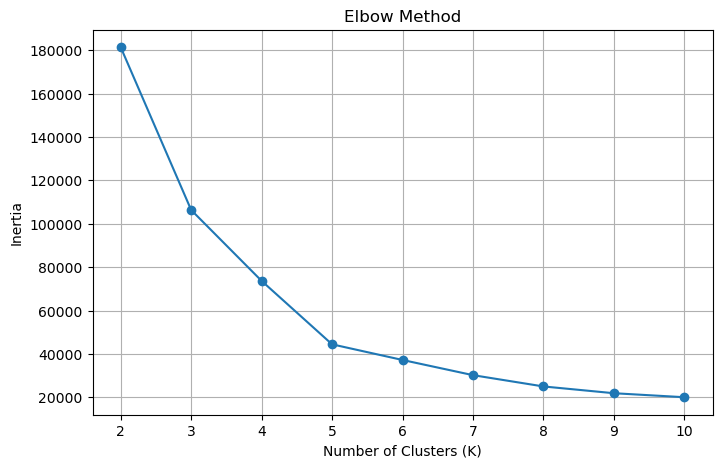

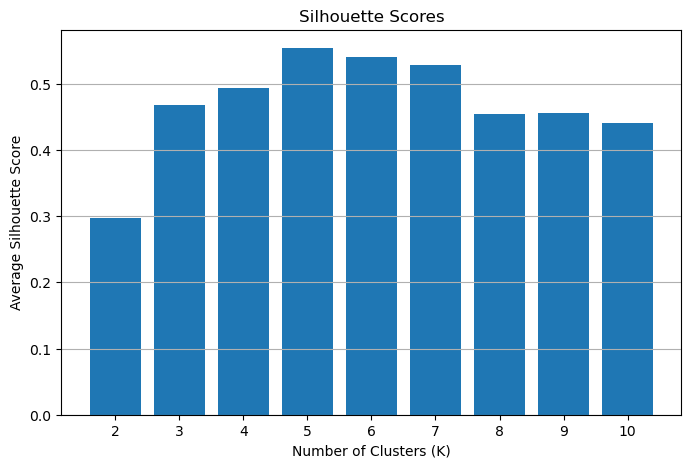

In [11]:
# YOUR CODE HERE

results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    )

    labels = model.fit_predict(X2)

    inertia = model.inertia_
    silhouette = silhouette_score(X2, labels)

    results.append([k, inertia, silhouette])


results_df = pd.DataFrame(
    results,
    columns=['K', 'Inertia', 'Silhouette']
)

print("Elbow and Silhouette Results:")
display(results_df)


best_k = results_df.loc[
    results_df['Silhouette'].idxmax(), 'K'
]

print("\nBest K according to Silhouette:", best_k)


# Plot 1: Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(
    results_df['K'],
    results_df['Inertia'],
    marker='o'
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()


# Plot 2: Silhouette Scores
plt.figure(figsize=(8, 5))
plt.bar(
    results_df['K'],
    results_df['Silhouette']
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Average Silhouette Score")
plt.title("Silhouette Scores")
plt.xticks(range(2, 11))
plt.grid(axis='y')
plt.show()

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [13]:
# YOUR CODE HERE

kmeans = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)

labels = kmeans.fit_predict(X2)

def calculate_silhouette(X, labels, point_index):

    point = X[point_index]
    own_cluster = labels[point_index]

    same_cluster = X[labels == own_cluster]
    same_cluster = same_cluster[
        np.arange(len(same_cluster)) != np.where(
            np.all(same_cluster == point, axis=1)
        )[0][0]
    ]

    a = np.linalg.norm(same_cluster - point, axis=1).mean()

    other_distances = []

    for cluster in np.unique(labels):
        if cluster != own_cluster:
            other_points = X[labels == cluster]

            avg_distance = np.linalg.norm(
                other_points - point, axis=1
            ).mean()

            other_distances.append(avg_distance)

    b = min(other_distances)

    s = (b - a) / max(a, b)

    return a, b, s


a, b, s = calculate_silhouette(X2, labels, 0)

sk_silhouette = silhouette_samples(X2, labels)[0]

print("Customer 1:")
print("a:", a)
print("b:", b)
print("Manual Silhouette:", s)
print("Scikit-learn Silhouette:", sk_silhouette)

Customer 1:
a: 24.64044215163639
b: 42.26526678748377
Manual Silhouette: 0.41700493041881637
Scikit-learn Silhouette: 0.4170049304188163


E:\AIML\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Cluster Silhouette Statistics:


,count,mean,min
Cluster,,,
0,81,0.596651,0.115294
1,39,0.509171,0.225413
2,22,0.599013,0.050721
3,35,0.503987,-0.023381
4,23,0.512268,-0.009278


Customers with Negative Silhouette: 2


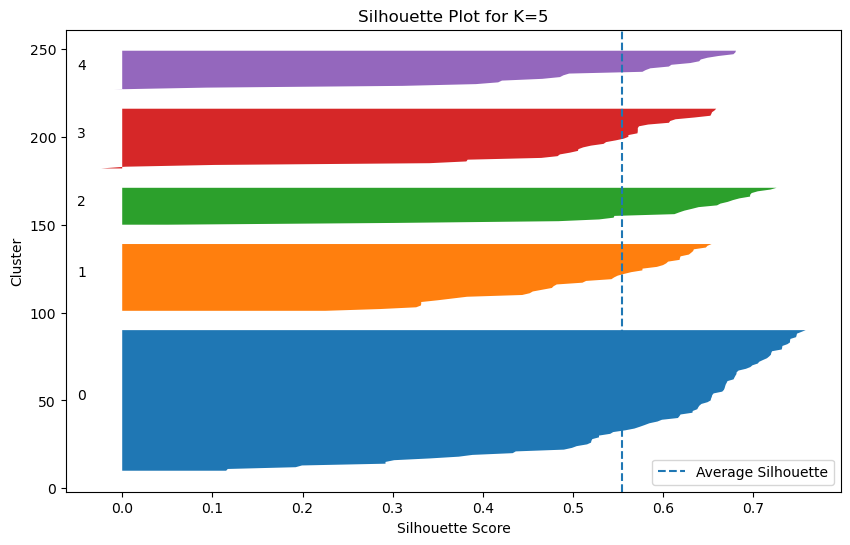

In [14]:
# YOUR CODE HERE

sil_values = silhouette_samples(X2, labels)

silhouette_df = pd.DataFrame({
    'Cluster': labels,
    'Silhouette': sil_values
})

print("Cluster Silhouette Statistics:")

display(
    silhouette_df.groupby('Cluster')['Silhouette']
    .agg(['count', 'mean', 'min'])
)

negative_count = np.sum(sil_values < 0)

print("Customers with Negative Silhouette:", negative_count)


plt.figure(figsize=(10, 6))

y_lower = 10

for cluster in np.unique(labels):

    cluster_values = sil_values[labels == cluster]
    cluster_values.sort()

    size = len(cluster_values)
    y_upper = y_lower + size

    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_values
    )

    plt.text(-0.05, y_lower + size / 2, str(cluster))

    y_lower = y_upper + 10

plt.axvline(
    np.mean(sil_values),
    linestyle='--',
    label='Average Silhouette'
)

plt.xlabel("Silhouette Score")
plt.ylabel("Cluster")
plt.title("Silhouette Plot for K=5")
plt.legend()
plt.show()

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [15]:
# YOUR CODE HERE

# Practice dataset
X_practice = np.array([
    [1], [3], [5], [7], [11], [13], [15]
], dtype=float)

initial_centroids = np.array([[1], [11]], dtype=float)

labels, centroids, inertia, iterations = my_kmeans(
    X_practice,
    initial_centroids
)


for k in range(len(centroids)):
    print(f"Cluster {k+1}:",
          X_practice[labels == k].flatten())

print("\nFinal Centroids:", centroids.flatten())
print("Inertia:", inertia)
print("Iterations:", iterations)


sk_scores = silhouette_samples(X_practice, labels)

print("\nSilhouette Calculations:")

for point in [1, 7, 11]:

    point_index = np.where(
        X_practice.flatten() == point
    )[0][0]

    a, b, s = calculate_silhouette(
        X_practice, labels, point_index
    )

    print(f"\nPoint: {point}")
    print("a:", a)
    print("b:", b)
    print("Manual Silhouette:", s)
    print("Sklearn Silhouette:", sk_scores[point_index])

Cluster 1: [1. 3. 5. 7.]
Cluster 2: [11. 13. 15.]

Final Centroids: [ 4. 13.]
Inertia: 28.0
Iterations: 3

Silhouette Calculations:

Point: 1
a: 4.0
b: 12.0
Manual Silhouette: 0.6666666666666666
Sklearn Silhouette: 0.6666666666666666

Point: 7
a: 4.0
b: 6.0
Manual Silhouette: 0.3333333333333333
Sklearn Silhouette: 0.3333333333333333

Point: 11
a: 3.0
b: 7.0
Manual Silhouette: 0.5714285714285714
Sklearn Silhouette: 0.5714285714285714


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

(a) Both suggest K = 5. Inertia decreases from 73,679.79 (K=4) to 44,448.46 (K=5), a drop of 29,231.33. From K=5 to K=6, it drops by 7,214.64.

(b) Customer 1 has a silhouette of 0.4170, indicating reasonable cluster placement. Cluster 3 has the weakest mean silhouette (0.5040), and 2 customers have negative values.

(c) Point 7 is less well placed because its silhouette is 0.3333, compared with 0.6667 for point 1. Its a=4 and b=6 indicate it is closer to the boundary between clusters.

(d) Inertia always decreases as K increases. Choosing the lowest inertia could produce too many clusters and unnecessary segmentation.


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


E:\AIML\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
E:\AIML\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
E:\AIML\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
E:\AIML\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less 

,Setting,Distinct Inertia Values,Lowest Inertia,Highest Inertia,Best Runs (%)
0,Random (n_init=1),14,44448.455448,91761.976192,33.333333
1,K-Means++ (n_init=1),6,44448.455448,66733.438571,60.000000
2,K-Means++ (n_init=10),1,44448.455448,44448.455448,100.000000


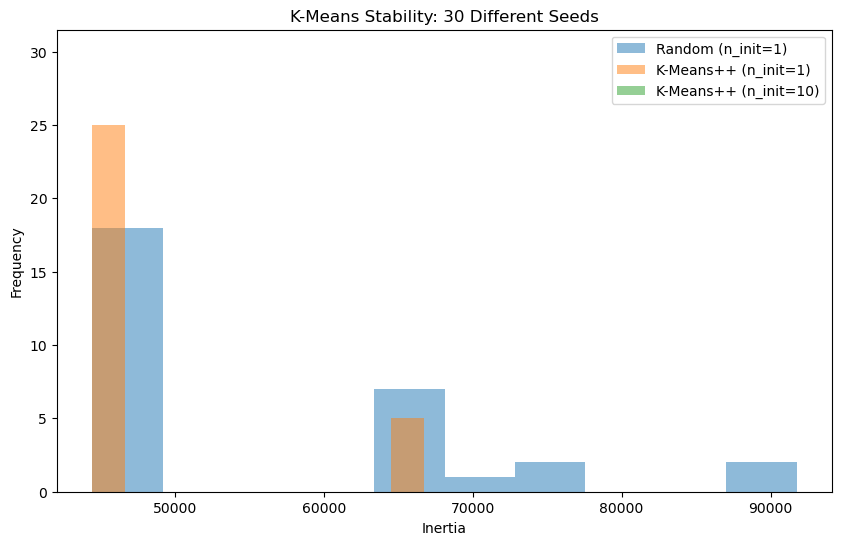

In [16]:
# YOUR CODE HERE

random_runs = []
kmeanspp_runs = []
kmeanspp10_runs = []

for seed in range(30):

    model_random = KMeans(
        n_clusters=5,
        init='random',
        n_init=1,
        random_state=seed
    )
    model_random.fit(X2)
    random_runs.append(model_random)

    model_kpp = KMeans(
        n_clusters=5,
        init='k-means++',
        n_init=1,
        random_state=seed
    )
    model_kpp.fit(X2)
    kmeanspp_runs.append(model_kpp)

    model_kpp10 = KMeans(
        n_clusters=5,
        init='k-means++',
        n_init=10,
        random_state=seed
    )
    model_kpp10.fit(X2)
    kmeanspp10_runs.append(model_kpp10)


settings = {
    'Random (n_init=1)': random_runs,
    'K-Means++ (n_init=1)': kmeanspp_runs,
    'K-Means++ (n_init=10)': kmeanspp10_runs
}

results = []

for name, runs in settings.items():

    inertias = np.array([model.inertia_ for model in runs])

    best_inertia = inertias.min()

    distinct_values = len(np.unique(np.round(inertias, 1)))

    best_percentage = (
        np.sum(np.isclose(inertias, best_inertia)) / len(inertias)
    ) * 100

    results.append([
        name,
        distinct_values,
        inertias.min(),
        inertias.max(),
        best_percentage
    ])


results_df = pd.DataFrame(
    results,
    columns=[
        'Setting',
        'Distinct Inertia Values',
        'Lowest Inertia',
        'Highest Inertia',
        'Best Runs (%)'
    ]
)

display(results_df)


plt.figure(figsize=(10, 6))

for name, runs in settings.items():

    inertias = [model.inertia_ for model in runs]

    plt.hist(
        inertias,
        bins=10,
        alpha=0.5,
        label=name
    )

plt.xlabel("Inertia")
plt.ylabel("Frequency")
plt.title("K-Means Stability: 30 Different Seeds")
plt.legend()
plt.show()

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


Best Run Inertia: 44448.45544793371
Worst Run Inertia: 91761.97619211908
Adjusted Rand Index: 0.45525713010305063


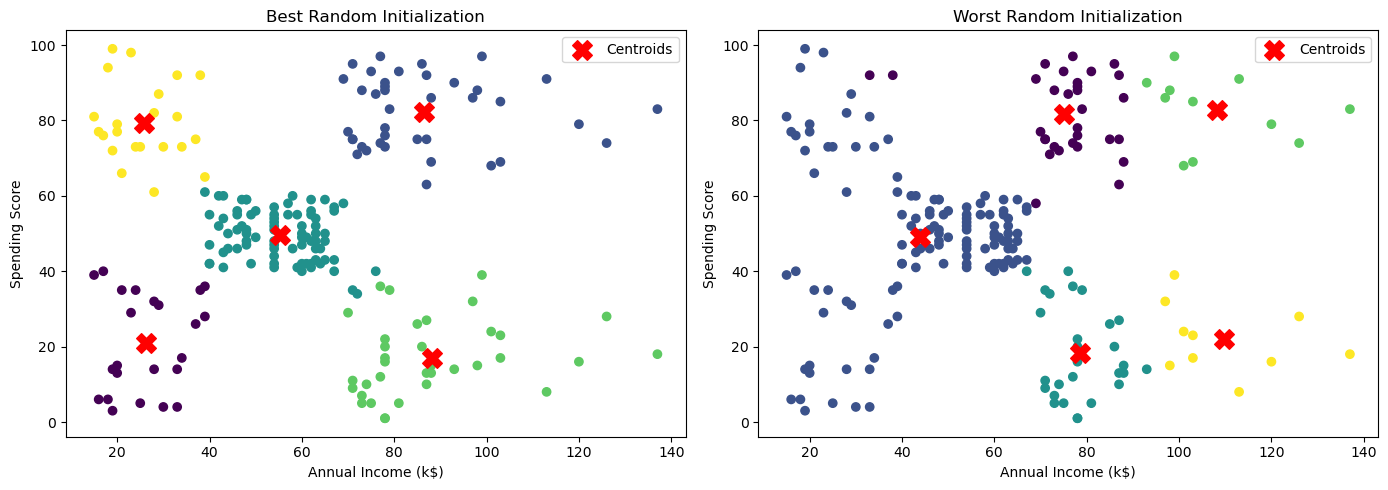

In [17]:
# YOUR CODE HERE

best_run = min(random_runs, key=lambda model: model.inertia_)
worst_run = max(random_runs, key=lambda model: model.inertia_)

ari = adjusted_rand_score(
    best_run.labels_,
    worst_run.labels_
)

print("Best Run Inertia:", best_run.inertia_)
print("Worst Run Inertia:", worst_run.inertia_)
print("Adjusted Rand Index:", ari)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

runs = [
    (best_run, "Best Random Initialization"),
    (worst_run, "Worst Random Initialization")
]

for ax, (model, title) in zip(axes, runs):

    ax.scatter(
        X2[:, 0],
        X2[:, 1],
        c=model.labels_,
        cmap='viridis'
    )

    ax.scatter(
        model.cluster_centers_[:, 0],
        model.cluster_centers_[:, 1],
        marker='X',
        s=200,
        color='red',
        label='Centroids'
    )

    ax.set_title(title)
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score")
    ax.legend()

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a) Random initialization produced 14 distinct inertia values, with 33.33% of runs reaching the best inertia. K-Means++ produced 6 values with 60% best runs, while K-Means++ with n_init=10 produced 1 value with 100% best runs.

(b) Different initial centroids can lead K-Means to different local minima, resulting in different cluster assignments and inertia values.

(c) K-Means++ selects better-spread initial centroids, while n_init runs K-Means multiple times and keeps the result with the lowest inertia. With n_init=10, all 30 runs achieved the best inertia of 44,448.46.

(d) Cluster labels are arbitrary. ARI compares the actual grouping structure regardless of cluster numbering. A score of 1 indicates identical groupings, while approximately 0 indicates random-level agreement.


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


In [ ]:
# YOUR CODE HERE


### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [ ]:
# YOUR CODE HERE


In [ ]:
# YOUR CODE HERE


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


In [ ]:
# YOUR CODE HERE


**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a)

(b)

(c)

(d)


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [ ]:
# YOUR CODE HERE


In [ ]:
# YOUR CODE HERE


### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [ ]:
# YOUR CODE HERE


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a)

(b)

(c)

(d)


---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [ ]:
# YOUR CODE HERE


In [ ]:
# YOUR CODE HERE


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [ ]:
# YOUR CODE HERE


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [ ]:
# YOUR CODE HERE


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

(a)

(b)

(c)

(d)


---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [ ]:
# YOUR CODE HERE


**Executive Summary** (6-8 lines)

*Your summary here.*


**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

(a)

(b)

(c)

(d)


---